# Notebook 06 — H3 Frozen Downstream Evaluation

Prospective, single-run frozen downstream evaluation of the selected H3 localizer
(epoch 54) through the frozen Stage-4D proposal policy and the frozen Phase-14
regional refiner (epoch 56), producing the **formal downstream R_H3**.

This notebook performs **no training and no inference**. It reads the frozen
downstream evaluation artifact and its saved per-component / per-image tables,
re-derives all aggregates, and asserts governance invariants.

**Final state:** `H3_DOWNSTREAM_EVALUATION_COMPLETE__FORMAL_ADJUDICATION_PENDING`

## 1. Executive Summary

In [1]:
import json, hashlib, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path('D:/Softfors/jup')
sys.path.insert(0, str(ROOT))
AUDITS = ROOT / 'reports' / 'audits'
TABLES = ROOT / 'reports' / 'tables'
FIGDIR = ROOT / 'reports' / 'figures'
FIGDIR.mkdir(parents=True, exist_ok=True)

def load_json(p): return json.loads((ROOT / p).read_text(encoding='utf-8'))
def sha(p): return hashlib.sha256((ROOT / p).read_bytes()).hexdigest()

down = load_json('reports/audits/h3_downstream_evaluation.json')
asrun = load_json('reports/audits/h3_downstream_evaluation_v1_asrun.json')
corr = load_json('reports/audits/h3_downstream_metric_domain_correction.json')
binding = load_json('reports/audits/h3_downstream_evaluator_binding.json')
supply = load_json('reports/audits/h3_supply_axis_evaluation.json')
recon = load_json('reports/audits/h3_supply_axis_metric_domain_reconciliation.json')
closure = load_json('reports/audits/h3_proposal_supply_training_closure.json')
replay = load_json('reports/audits/h3_checkpoint_selection_replay.json')

comp_df = pd.read_csv(TABLES / 'h3_downstream_per_component.csv')
img_df = pd.read_csv(TABLES / 'h3_downstream_per_image.csv')
frozen_summary = pd.read_csv(TABLES / 'phase14_clean_v3_mode_summary.csv').set_index('mode')

fd = down['formal_downstream']
print('STATUS                        :', down['status'])
print('TinyRecall_H3 (formal, det)   :', fd['TinyRecall_H3'], '=', fd['TinyRecall_H3_fraction'])
print('Tg / G                        :', fd['Tg'], '/', fd['G'])
print('R_H3 (formal, detection)      :', fd['R_H3'], '->', fd['interpretation_band'])
print('R_H3 (strict cov90 sensitivity):', fd['sensitivity_strict_cov90']['R_H3_cov90'])
print('Formal adjudication performed :', down['formal_adjudication_performed'])
print('TEST reads / external reads   :', down['test_reads'], '/', down['external_test_reads'])
print('Phase 15                      :', down['phase_15_status'])

STATUS                        : H3_DOWNSTREAM_EVALUATION_COMPLETE__FORMAL_ADJUDICATION_PENDING
TinyRecall_H3 (formal, det)   : 0.8194444444444444 = 59/72
Tg / G                        : 0.7916666666666666 / 0.20833333333333337
R_H3 (formal, detection)      : 0.13333333333333336 -> insufficient
R_H3 (strict cov90 sensitivity): -1.3999999999999995
Formal adjudication performed : False
TEST reads / external reads   : 0 / 0
Phase 15                      : NOT_STARTED_AND_NOT_AUTHORIZED


## 2. Current Governance State

In [2]:
rows = [
    ('H3 training (Notebook 04)', closure['status'], f"epochs={closure['total_epochs']} best_epoch={closure['best_epoch']}"),
    ('Checkpoint-selection replay', replay['verdict'], 'deterministic re-derivation'),
    ('H3 supply-axis evaluation (NB05)', supply['status'], 'localizer/proposal supply only'),
    ('NB05 metric-domain reconciliation', recon['status'], 'proxy relabelled; downstream R_H3 was PENDING'),
    ('H3 downstream evaluation (NB06)', down['status'], 'this notebook'),
    ('Formal H3 adjudication (NB07)', 'NOT_STARTED', 'requires separate supervisor authorization'),
    ('Phase 15', down['phase_15_status'], 'not authorized'),
    ('TEST split', 'CLOSED', '0 content reads'),
]
display(pd.DataFrame(rows, columns=['item', 'state', 'detail']))
print('Notebook 06 is the frozen downstream evaluation record. It is NOT the formal adjudication.')

,item,state,detail
0,H3 training (Notebook 04),H3_TRAINING_COMPLETE__CHECKPOINT_SELECTION_REP...,epochs=69 best_epoch=54
1,Checkpoint-selection replay,H3_CHECKPOINT_SELECTION_REPLAY_PASS,deterministic re-derivation
2,H3 supply-axis evaluation (NB05),H3_SUPPLY_AXIS_EVALUATION_COMPLETE__FORMAL_ADJ...,localizer/proposal supply only
3,NB05 metric-domain reconciliation,H3_SUPPLY_METRIC_DOMAIN_RECONCILED__DOWNSTREAM...,proxy relabelled; downstream R_H3 was PENDING
4,H3 downstream evaluation (NB06),H3_DOWNSTREAM_EVALUATION_COMPLETE__FORMAL_ADJU...,this notebook
5,Formal H3 adjudication (NB07),NOT_STARTED,requires separate supervisor authorization
6,Phase 15,NOT_STARTED_AND_NOT_AUTHORIZED,not authorized
7,TEST split,CLOSED,0 content reads


Notebook 06 is the frozen downstream evaluation record. It is NOT the formal adjudication.


## 3. H3 Checkpoint Binding

In [3]:
ck = down['selected_h3_checkpoint']
ck_path = ROOT / ck['path']
ck_sha_disk = hashlib.sha256(ck_path.read_bytes()).hexdigest()
print('path            :', ck['path'])
print('selected epoch  :', ck['selected_epoch'])
print('heatmap res     :', ck['heatmap_resolution'])
print('construction    :', ck['construction'])
print('sha (artifact)  :', ck['sha256'])
print('sha (disk)      :', ck_sha_disk)
print('match           :', ck_sha_disk == ck['sha256'])
print()
print('refiner :', down['refiner_checkpoint']['sha256'], 'epoch', down['refiner_checkpoint']['epoch'])
print('global  :', down['global_checkpoint']['sha256'])

path            : D:\Softfors\jup\checkpoints\h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3\best.pt
selected epoch  : 54
heatmap res     : 128
construction    : build_clean_v3_localizer (explicit heatmap_resolution=128)
sha (artifact)  : d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e4d6e01f30345eca75e
sha (disk)      : d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e4d6e01f30345eca75e
match           : True

refiner : 2e09e3a9c39c731687db1a9fef0c80881ed6235e4cda070bb4b8b382caa45daa epoch 56
global  : ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b4a3653f3e4d1283269


## 4. Frozen Downstream Pipeline Definition

In [4]:
pipeline = [
    'H3 localizer (epoch 54) -> 128-space heatmap (heatmap_resolution=128)',
    'frozen Stage-4D proposal policy: threshold=0.10, margin=0.20, top_k=5, nms_iou=0.30',
    'Phase-14 regional refiner (epoch 56) applied per proposal crop (256)',
    'MAX-probability replacement inside the proposal union (aggregate_and_fuse)',
    'FULL_FIELD segmentation at threshold 0.50',
    'per-component / per-size downstream metrics',
    'formal R_H3 = (TinyRecall_H3 - Tg) / G',
]
for i, step in enumerate(pipeline, 1):
    print(f'{i}. {step}')
print()
print('fusion semantics :', down['evaluator_binding']['fusion_semantics'])
print('fusion threshold :', down['evaluator_binding']['final_fusion_threshold'])
print('global threshold :', down['evaluator_binding']['global_threshold'])
print('proposal configs evaluated:', down['proposal_configurations_evaluated'])

1. H3 localizer (epoch 54) -> 128-space heatmap (heatmap_resolution=128)
2. frozen Stage-4D proposal policy: threshold=0.10, margin=0.20, top_k=5, nms_iou=0.30
3. Phase-14 regional refiner (epoch 56) applied per proposal crop (256)
4. MAX-probability replacement inside the proposal union (aggregate_and_fuse)
5. FULL_FIELD segmentation at threshold 0.50
6. per-component / per-size downstream metrics
7. formal R_H3 = (TinyRecall_H3 - Tg) / G

fusion semantics : MAX probability replacement inside proposal union (aggregate_and_fuse)
fusion threshold : 0.5
global threshold : 0.5
proposal configs evaluated: 1


## 5. Frozen Proposal Policy

In [5]:
policy = down['frozen_proposal_policy']
print('frozen proposal policy:', policy)
assert policy == {'threshold': 0.10, 'margin': 0.20, 'top_k': 5, 'nms_iou': 0.30}
print('Exactly ONE policy was evaluated (no search):', down['proposal_configurations_evaluated'] == 1)

frozen proposal policy: {'threshold': 0.1, 'margin': 0.2, 'top_k': 5, 'nms_iou': 0.3}
Exactly ONE policy was evaluated (no search): True


## 6. Refiner & Fusion Rules

In [6]:
print('refiner checkpoint epoch :', down['refiner_checkpoint']['epoch'])
print('refiner crop target size :', down['evaluator_binding']['refiner_crop_target_size'])
print('fusion                   :', down['evaluator_binding']['fusion_semantics'])
print('final fusion threshold   :', down['evaluator_binding']['final_fusion_threshold'])
print()
print('These are byte-identical to the bound Phase-14 clean-v3 evaluator; only the')
print('localizer checkpoint (and its training-faithful 128 heatmap construction) changed.')

refiner checkpoint epoch :

 56
refiner crop target size : 256
fusion                   : MAX probability replacement inside proposal union (aggregate_and_fuse)
final fusion threshold   : 0.5

These are byte-identical to the bound Phase-14 clean-v3 evaluator; only the
localizer checkpoint (and its training-faithful 128 heatmap construction) changed.


## 7. Evaluator Prospective Binding

In [7]:
eb = binding['evaluator']
print('binding status      :', binding['status'])
print('evaluator path      :', eb['path'])
print('evaluator sha (bind):', eb['sha256'])
print('evaluator sha (disk):', sha(eb['path']))
print('binding intact      :', sha(eb['path']) == eb['sha256'])
print()
print('bound checkpoints   :', json.dumps(binding['bound_checkpoints'], indent=1))
print('h3_heatmap_resolution:', binding['h3_heatmap_resolution'])
print('formal_R_H3_source  :', binding['formal_R_H3_source'])
print()
print('NOTE: the binding recorded the metric as', repr(binding['metric_definitions']['downstream_recall90']))
print('      which is the strict-coverage definition. Section 11 reconciles the domain.')

binding status      : BOUND_PROSPECTIVE__BEFORE_RESULTS
evaluator path      : scripts/evaluation/h3_downstream_evaluator.py
evaluator sha (bind): 5afb3d9419ebebd2096ed29c52fe744af6197e5260ed1f8d91f9e7de61688a1d
evaluator sha (disk): 5afb3d9419ebebd2096ed29c52fe744af6197e5260ed1f8d91f9e7de61688a1d
binding intact      : True

bound checkpoints   : {
 "h3_localizer_epoch54": "d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e4d6e01f30345eca75e",
 "phase14_refiner_epoch56": "2e09e3a9c39c731687db1a9fef0c80881ed6235e4cda070bb4b8b382caa45daa",
 "phase10_global_epoch70": "ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b4a3653f3e4d1283269"
}
h3_heatmap_resolution: 128
formal_R_H3_source  : DOWNSTREAM_TINY_RECALL

NOTE: the binding recorded the metric as 'overlap/component_pixels>=0.90'
      which is the strict-coverage definition. Section 11 reconciles the domain.


## 8. Reused Frozen References

In [8]:
ref = down['frozen_references']
print('Frozen downstream references:', ref)
gref = load_json('reports/audits/phase14_clean_v3_global_reference_freeze.json')
print()
print('GLOBAL reference freeze status:', gref['status'])
print('Tg definition (authoritative) :', gref['derivation']['Tg_definition'])
print('Dg definition                 :', gref['derivation']['Dg_definition'])
print()
print('GLOBAL / PREDICTED / ORACLE rows are REUSED verbatim from')
print('reports/tables/phase14_clean_v3_mode_summary.csv (frozen Phase-14 artifact).')

Frozen downstream references:

 {'Tg': 0.7916666666666666, 'G': 0.20833333333333337, 'Dg': 0.6359172411726776}

GLOBAL reference freeze status: FROZEN
Tg definition (authoritative) : GLOBAL_ONLY Tiny Recall@90 = mean over TINY components of (global mask >=1px overlap) — identical semantics to v2-era evaluate_phase14_diagnostic.py
Dg definition                 : GLOBAL_ONLY mean Dice over the 103-image FULL_FIELD VAL population

GLOBAL / PREDICTED / ORACLE rows are REUSED verbatim from
reports/tables/phase14_clean_v3_mode_summary.csv (frozen Phase-14 artifact).


## 9. Evaluation Population

In [9]:
pop = down['population']
print('population:', json.dumps(pop, indent=1))
print()
print('per-component table rows :', len(comp_df))
print('per-image table rows     :', len(img_df))
print('size stratum counts      :', comp_df['size_stratum'].value_counts().to_dict())

population:

 {
 "view_type": "FULL_FIELD",
 "val_images": 103,
 "components": 152,
 "size_strata": {
  "TINY": 72,
  "SMALL": 28,
  "MEDIUM": 36,
  "LARGE": 16
 },
 "hard_tiny_denominator": 15,
 "global_empty_denominator": 5
}

per-component table rows : 152
per-image table rows     : 103
size stratum counts      : {'TINY': 72, 'MEDIUM': 36, 'SMALL': 28, 'LARGE': 16}


## 10. Primary Downstream Metric Definition

In [10]:
pm = down['primary_metric_definition']
print('name              :', pm['name'])
print('frozen domain     :', pm['frozen_domain'])
print('formal value      :', pm['formal_TinyRecall_H3'], '=', pm['formal_TinyRecall_H3_fraction'])
print()
print('definition        :', pm['definition'])
print()
print('explicitly NOT    :', pm['not_the_proposal_coverage'])

name              :

 H3_DOWNSTREAM_TINY_RECALL90
frozen domain     : DETECTION (component overlap >= 1 pixel)
formal value      : 0.8194444444444444 = 59/72

definition        : Mean over the 72 canonical clean-v3 FULL_FIELD VAL TINY GT components of (H3 downstream fused FULL_FIELD mask overlap >= 1 px). Identical semantics to the frozen Phase-14 GLOBAL/PREDICTED/ORACLE reference.

explicitly NOT    : This is a DOWNSTREAM segmentation quantity (post-refiner fusion), not the localizer-only proposal coverage90.


## 11. Metric-Domain Reconciliation (cov90 vs detection)

In [11]:
mdc = down['metric_domain_correction']
print('correction nature :', mdc['nature'])
print('inference re-run  :', mdc['inference_rerun'])
print()
print('AUTHORITATIVE SOURCE:')
print('  ', mdc['authoritative_source']['path'])
print('  ', mdc['authoritative_source']['Tg_definition'])
print('  ', mdc['authoritative_source']['numeric_confirmation'])
print()
print('DEFECT ORIGIN:')
print('  ', mdc['defect_origin'])
print()
print('WHY DETECTION IS FORMAL:')
print('  ', mdc['why_detection_is_formal'])
print()
print('AS-RUN (superseded) artifact:')
asr = mdc['asrun_artifact_preserved']
print('   path  :', asr['path'])
print('   R_H3  :', asr['formal_R_H3_asrun_cov90'])
print('   status:', asr['status_of_asrun_formal_block'])

correction nature :

 ADDITIVE_METRIC_LAYER_CORRECTION__NO_NEW_INFERENCE
inference re-run  : False

AUTHORITATIVE SOURCE:
   reports/audits/phase14_clean_v3_global_reference_freeze.json
   GLOBAL_ONLY Tiny Recall@90 = mean over TINY components of (global mask >=1px overlap)
   Tg = 57/72 = 0.7916666666666666 (detection), not 14/72 = 0.1944 (>=90% coverage)

DEFECT ORIGIN:
   reports/audits/h3_downstream_evaluator_binding.json bound the metric definition as 'downstream_recall90 = overlap/component_pixels>=0.90' (strict coverage). That definition is inconsistent with the earlier-frozen reference Tg = 0.7916666666666666, which is the DETECTION criterion (>=1px overlap) per reports/audits/phase14_clean_v3_global_reference_freeze.json. Using a strict-coverage TinyRecall_H3 against a detection-domain Tg and a detection-domain gap G is a category error: the numerator and denominator are in different metric domains.

WHY DETECTION IS FORMAL:
   R_H3 = (TinyRecall_H3 - Tg) / G is only meaningful when TinyRecall_H3,

## 12. H3 Downstream Aggregate Metrics

In [12]:
m = down['h3_downstream_metrics']
rows = [
    ('mean Dice', m['mean_dice']),
    ('median Dice', m['median_dice']),
    ('overall recall@90 (detection)', m['overall_recall90_det']),
    ('TINY recall@90 (detection)', m['tiny_recall90_det']),
    ('SMALL recall@90 (detection)', m['small_recall90_det']),
    ('MEDIUM recall@90 (detection)', m['medium_recall90_det']),
    ('LARGE recall@90 (detection)', m['large_recall90_det']),
    ('hard-Tiny recovered', f"{m['hard_tiny_recovered']}/{m['hard_tiny_total']}"),
    ('global-empty recovered', f"{m['global_empty_recovered']}/{m['global_empty_total']}"),
    ('mean FP components/image', m['mean_fp_components_per_image']),
]
display(pd.DataFrame(rows, columns=['metric', 'value']))
print('Strict cov90 (descriptive only):')
c = m['descriptive_strict_cov90']
print('   overall', c['overall_cov90'], '| TINY', c['tiny_cov90'], '| SMALL', c['small_cov90'],
      '| MEDIUM', c['medium_cov90'], '| LARGE', c['large_cov90'])

,metric,value
0,mean Dice,0.388628
1,median Dice,0.36936
2,overall recall@90 (detection),0.901316
3,TINY recall@90 (detection),0.819444
4,SMALL recall@90 (detection),0.964286
5,MEDIUM recall@90 (detection),1.0
6,LARGE recall@90 (detection),0.9375
7,hard-Tiny recovered,5/15
8,global-empty recovered,3/5
9,mean FP components/image,7.572816


Strict cov90 (descriptive only):
   overall 0.42105263157894735 | TINY 0.5 | SMALL 0.4642857142857143 | MEDIUM 0.3888888888888889 | LARGE 0.0625


## 13. Complete Per-Component Table (152 rows)

In [13]:
print('Per-component table:', len(comp_df), 'rows')
det = comp_df['h3_downstream_overlap_pixels'].astype(int) >= 1
comp_view = comp_df.assign(h3_det_success=det)
display(comp_view.head(20))
print('...')
print('columns:', list(comp_df.columns))

Per-component table:

 152 rows


,sample_id,component_id,size_stratum,component_area,h3_downstream_recall90_success,h3_downstream_overlap_pixels,h3_downstream_coverage_ratio,h3_proposal_any_overlap,h3_proposal_best_coverage,hard_tiny_flag,global_empty_flag,h3_det_success
0,66b947d8ead11ae1260bc3142ca1707d,1,TINY,522,True,518,0.992337,False,0.000000,False,False,True
1,608acc38d4a151803e72f2f033ade67e,1,MEDIUM,4955,True,4538,0.915843,True,1.000000,False,False,True
2,774123a57e11f802de7ed923c13b7120,1,TINY,841,True,841,1.000000,True,1.000000,False,False,True
3,68509b1fa766f0a9bb074a3640f5ea05,1,TINY,848,True,848,1.000000,True,1.000000,False,False,True
4,f5a92a209cd5010d230ecaab8556ef89,1,TINY,1088,True,1032,0.948529,True,1.000000,False,False,True
5,5bd7da98325290a26350ed2e92fde011,1,TINY,559,True,534,0.955277,False,0.000000,False,False,True
6,1ba084b5439ffee651b4f5e0697e2209,1,TINY,649,False,306,0.471495,True,0.257919,False,False,True
7,64fa38b86930065b413e12b8c8308745,1,TINY,709,True,709,1.000000,True,1.000000,False,False,True
8,32c06da36a7221dc5369e3ee4723c10c,1,TINY,1145,False,1004,0.876856,True,1.000000,False,False,True
9,32c06da36a7221dc5369e3ee4723c10c,2,TINY,1047,True,965,0.921681,True,1.000000,False,False,True


...
columns: ['sample_id', 'component_id', 'size_stratum', 'component_area', 'h3_downstream_recall90_success', 'h3_downstream_overlap_pixels', 'h3_downstream_coverage_ratio', 'h3_proposal_any_overlap', 'h3_proposal_best_coverage', 'hard_tiny_flag', 'global_empty_flag']


## 14. Complete Per-Image Table (103 rows)

In [14]:
print('Per-image table:', len(img_df), 'rows')
display(img_df.head(20))
print('...')
print('columns:', list(img_df.columns))

Per-image table:

 103 rows


,sample_id,patient_id,category,global_dice,h3_downstream_dice,global_fp_components,h3_downstream_fp_components,h3_proposals,h3_roi_area_fraction,h3_zero_proposal_gt_components,h3_zero_proposal_tiny_components,h3_empty_pred_flag,has_hard_tiny,global_empty,global_time_ms,localizer_time_ms,refiner_time_ms,fusion_time_ms
0,66b947d8ead11ae1260bc3142ca1707d,patient-00001,Bladder_Stone,7.716895e-01,1.638463e-01,0,6,5,0.003863,1,1,False,False,False,1528.1114,522.9283,308.2621,194.5959
1,608acc38d4a151803e72f2f033ade67e,patient-00002,Bladder_Stone,8.866140e-01,7.801272e-01,0,6,5,0.006486,0,0,False,False,False,145.0910,30.1774,166.5738,150.5474
2,774123a57e11f802de7ed923c13b7120,patient-00007,Bladder_Stone,8.374497e-01,3.448842e-01,0,3,5,0.002652,0,0,False,False,False,134.0149,25.0616,148.7869,140.0418
3,68509b1fa766f0a9bb074a3640f5ea05,patient-00011,Bladder_Stone,6.935484e-01,3.765542e-01,1,9,5,0.004065,0,0,False,False,False,129.3354,28.3716,145.2028,130.4455
4,f5a92a209cd5010d230ecaab8556ef89,patient-00012,Bladder_Stone,7.076547e-01,4.522349e-01,1,5,5,0.002652,0,0,False,False,False,170.8169,31.8642,160.8832,118.6354
5,5bd7da98325290a26350ed2e92fde011,patient-00013,Bladder_Stone,7.491216e-01,8.565242e-02,0,14,5,0.009001,1,1,False,False,False,187.5236,33.7224,158.0129,119.2103
6,1ba084b5439ffee651b4f5e0697e2209,patient-00014,Bladder_Stone,6.536485e-01,4.723680e-02,0,9,5,0.005110,0,0,False,False,False,198.9701,30.2015,148.7357,114.3904
7,64fa38b86930065b413e12b8c8308745,patient-00023,Bladder_Stone,8.448145e-01,1.706789e-01,0,15,5,0.004762,0,0,False,False,False,173.2237,29.1723,155.4246,113.5570
8,32c06da36a7221dc5369e3ee4723c10c,patient-00041,Bladder_Stone,7.611940e-01,4.734311e-01,1,6,5,0.004634,0,0,False,False,False,173.1835,30.6038,144.7731,123.0734
9,f1afd69d82aff6da8bc39cdcd5f90bf6,patient-00044,Bladder_Stone,5.739464e-01,3.430377e-01,5,5,5,0.009844,0,0,False,False,False,398.7294,26.2635,133.6432,117.7772


...
columns: ['sample_id', 'patient_id', 'category', 'global_dice', 'h3_downstream_dice', 'global_fp_components', 'h3_downstream_fp_components', 'h3_proposals', 'h3_roi_area_fraction', 'h3_zero_proposal_gt_components', 'h3_zero_proposal_tiny_components', 'h3_empty_pred_flag', 'has_hard_tiny', 'global_empty', 'global_time_ms', 'localizer_time_ms', 'refiner_time_ms', 'fusion_time_ms']


## 15. Size-Stratified Downstream Recall

In [15]:
det = comp_df['h3_downstream_overlap_pixels'].astype(int) >= 1
cov = comp_df['h3_downstream_coverage_ratio'].astype(float) >= 0.90
rows = []
for g in ['TINY', 'SMALL', 'MEDIUM', 'LARGE']:
    s = comp_df['size_stratum'].eq(g)
    rows.append({
        'size': g,
        'n': int(s.sum()),
        'det_count': int(det[s].sum()),
        'det_recall': float(det[s].mean()),
        'cov90_count': int(cov[s].sum()),
        'cov90_recall': float(cov[s].mean()),
    })
strat = pd.DataFrame(rows)
display(strat)
print('detection domain = frozen formal domain; cov90 = descriptive strict sensitivity.')

,size,n,det_count,det_recall,cov90_count,cov90_recall
0,TINY,72,59,0.819444,36,0.500000
1,SMALL,28,27,0.964286,13,0.464286
2,MEDIUM,36,36,1.000000,14,0.388889
3,LARGE,16,15,0.937500,1,0.062500


detection domain = frozen formal domain; cov90 = descriptive strict sensitivity.


## 16. Contrast Table (GLOBAL / PREDICTED / H3 / ORACLE)

In [16]:
ct = down['contrast_table']
rows = []
for key in ['GLOBAL', 'PREDICTED', 'H3', 'ORACLE_REGIONAL']:
    r = ct[key]
    rows.append({
        'arm': key,
        'source': r['source'],
        'mean_dice': r['mean_dice'],
        'overall_det': r['overall_recall90_det'],
        'tiny_det': r['tiny_recall90_det'],
        'small_det': r['small_recall90_det'],
        'medium_det': r['medium_recall90_det'],
        'large_det': r['large_recall90_det'],
        'hard_tiny': r['hard_tiny_recovered'],
        'global_empty': r['global_empty_recovered'],
        'mean_fp_img': r['mean_fp_components_per_image'],
    })
contrast_df = pd.DataFrame(rows)
display(contrast_df)
print()
print('H3 strict cov90 (descriptive): TINY', ct['H3']['tiny_cov90'], '| overall', ct['H3']['overall_cov90'])

,arm,source,mean_dice,overall_det,tiny_det,small_det,medium_det,large_det,hard_tiny,global_empty,mean_fp_img
0,GLOBAL,REUSED (phase14_clean_v3_mode_summary.csv),0.635917,0.822368,0.791667,0.821429,0.861111,0.8750,0,0,0.485437
1,PREDICTED,REUSED (phase14_clean_v3_mode_summary.csv),0.418531,0.875000,0.791667,0.892857,1.000000,0.9375,0,1,7.776699
2,H3,NEWLY GENERATED (single frozen H3 downstream e...,0.388628,0.901316,0.819444,0.964286,1.000000,0.9375,5,3,7.572816
3,ORACLE_REGIONAL,REUSED (phase14_clean_v3_mode_summary.csv),0.802416,1.000000,1.000000,1.000000,1.000000,1.0000,15,5,0.631068



H3 strict cov90 (descriptive): TINY 0.5 | overall 0.42105263157894735


## 17. Formal TinyRecall_H3

In [17]:
fd = down['formal_downstream']
print('TinyRecall_H3 :', fd['TinyRecall_H3'])
print('fraction      :', fd['TinyRecall_H3_fraction'])
print('metric domain :', fd['metric_domain'])
print()
print('Definition: mean over the 72 TINY components of (fused FULL_FIELD mask')
print('overlap >= 1 px) -- identical semantics to the frozen GLOBAL/PREDICTED/ORACLE rows.')

TinyRecall_H3 : 0.8194444444444444
fraction      : 59/72
metric domain : DETECTION (>=1px overlap) -- frozen-consistent

Definition: mean over the 72 TINY components of (fused FULL_FIELD mask
overlap >= 1 px) -- identical semantics to the frozen GLOBAL/PREDICTED/ORACLE rows.


## 18. Formal R_H3

In [18]:
print('R_H3 = (TinyRecall_H3 - Tg) / G')
print(f"     = ({fd['TinyRecall_H3']} - {fd['Tg']}) / {fd['G']}")
print(f"     = {fd['R_H3']}")
print('exact fraction:', fd['R_H3_exact_fraction'])
print('band          :', fd['interpretation_band'])
print()
sens = fd['sensitivity_strict_cov90']
print('SENSITIVITY (strict cov90, NOT formal):')
print('   TinyRecall_H3_cov90 =', sens['TinyRecall_H3_cov90'])
print('   R_H3_cov90          =', sens['R_H3_cov90'], '->', sens['interpretation_band_cov90'])

R_H3 = (TinyRecall_H3 - Tg) / G


     = (0.8194444444444444 - 0.7916666666666666) / 0.20833333333333337
     = 0.13333333333333336
exact fraction: 2/15
band          : insufficient

SENSITIVITY (strict cov90, NOT formal):
   TinyRecall_H3_cov90 = 0.5
   R_H3_cov90          = -1.3999999999999995 -> insufficient


## 19. Interpretation Band

In [19]:
bands = [
    ('meaningful', 'R_H3 >= 0.30', fd['R_H3'] >= 0.30),
    ('intermediate', '0.15 <= R_H3 < 0.30', 0.15 <= fd['R_H3'] < 0.30),
    ('insufficient', 'R_H3 < 0.15', fd['R_H3'] < 0.15),
]
for name, rule, hit in bands:
    print(f"  {name:14s} {rule:24s} -> {'ACTIVE' if hit else ''}")
print()
print('Formal band:', fd['interpretation_band'])

  meaningful     R_H3 >= 0.30             -> 


  intermediate   0.15 <= R_H3 < 0.30      -> 
  insufficient   R_H3 < 0.15              -> ACTIVE

Formal band: insufficient


## 20. Supply-Agreement Check

In [20]:
sa = down['supply_agreement_check']
print('expected  zero-proposal GT / TINY :', sa['expected_zero_proposal_gt'], '/', sa['expected_zero_proposal_tiny'])
print('recomputed zero-proposal GT / TINY:', sa['recomputed_zero_proposal_gt'], '/', sa['recomputed_zero_proposal_tiny'])
print('by size (recomputed):', sa['recomputed_zero_proposal_by_size'])
print('deterministic agreement:', sa['deterministic_agreement'])
print()
print('Discrepancy note:')
print(' ', sa['discrepancy'])

expected  zero-proposal GT / TINY :

 27 / 22
recomputed zero-proposal GT / TINY: 26 / 21
by size (recomputed): {'TINY': 21, 'SMALL': 3, 'MEDIUM': 1, 'LARGE': 1}
deterministic agreement: False

Discrepancy note:
  Off-by-one on TINY only (21 vs 22; SMALL/MEDIUM/LARGE agree exactly). Root cause: GT component bbox provenance. The supply-axis evaluator sourced GT bboxes from reports/tables/phase13_predicted_roi_per_component.csv, whereas this downstream evaluator uses extract_gt_components(raw_mask) (the frozen Phase-14 method). One TINY component's bbox is an edge case between the two provenances. The supply gates are already INVALID_FOR_FORMAL_ADJUDICATION and are not used here.


## 21. Hard-Tiny Recovery

In [21]:
m = down['h3_downstream_metrics']
print('hard-Tiny recovered (detection) :', m['hard_tiny_recovered'], '/', m['hard_tiny_total'])
print('hard-Tiny recovered (cov90)     :', m['descriptive_strict_cov90']['hard_tiny_recovered_cov90'], '/ 15')
print()
ht = comp_df[comp_df['hard_tiny_flag'].astype(bool)]
print('hard-Tiny components:', len(ht))
display(ht[['sample_id', 'component_id', 'component_area', 'h3_downstream_overlap_pixels', 'h3_downstream_coverage_ratio']])

hard-Tiny recovered (detection) : 5 / 15
hard-Tiny recovered (cov90)     : 2 / 15

hard-Tiny components: 15


,sample_id,component_id,component_area,h3_downstream_overlap_pixels,h3_downstream_coverage_ratio
19,2286db1a7e6b8867cde46a4294ba0c10,2,722,0,0.000000
21,b0473630de9211114c94c7dc0363ebd9,1,954,206,0.215933
35,8c8d2107815002b7913bd6a42f93b394,1,319,308,0.965517
36,8c8d2107815002b7913bd6a42f93b394,2,183,69,0.377049
38,ec7d4690db3c071ecd012b3594d757be,2,398,0,0.000000
39,ad4af1ce1b3dde6ad04fa095aacd92f5,1,569,0,0.000000
43,9f367e7db192bfe532ace746fd788fb9,2,1402,0,0.000000
66,6a5d5c051d6c898d98c90422da190bf0,2,409,0,0.000000
68,a626dd389032147c7d4ebd2b1db39e45,1,866,0,0.000000
70,f860cbfe7c79e5772795a64bac5de7e7,1,697,666,0.955524


## 22. Global-Empty Recovery

In [22]:
m = down['h3_downstream_metrics']
print('global-empty recovered (detection) :', m['global_empty_recovered'], '/', m['global_empty_total'])
print('global-empty recovered (cov90)     :', m['descriptive_strict_cov90']['global_empty_recovered_cov90'], '/ 5')
ge = img_df[img_df['global_empty'].astype(bool)]
display(ge[['sample_id', 'global_dice', 'h3_downstream_dice', 'h3_proposals', 'h3_empty_pred_flag']])

global-empty recovered (detection) :

 3 / 5
global-empty recovered (cov90)     : 1 / 5


,sample_id,global_dice,h3_downstream_dice,h3_proposals,h3_empty_pred_flag
16,b0473630de9211114c94c7dc0363ebd9,1.048218e-10,1.842576e-01,5,False
24,8c8d2107815002b7913bd6a42f93b394,1.992032e-10,1.702032e-01,5,False
26,ad4af1ce1b3dde6ad04fa095aacd92f5,1.757469e-10,4.553734e-11,4,False
92,5dd4436a2065b8855ce1dfbed228bce7,3.927730e-11,1.887231e-01,5,False
99,416e6f7d9e35c6bf4bde51e191a7e92d,1.960784e-10,1.924928e-11,5,False


## 23. Proposal Burden

In [23]:
pb = down['h3_downstream_metrics']['proposal_burden']
display(pd.DataFrame(list(pb.items()), columns=['metric', 'value']))
print()
print('H3 proposal counts vs frozen PREDICTED (phase14 mode summary):')
print('  H3 mean proposals/image        :', pb['mean_proposals_per_image'])
print('  PREDICTED mean proposals/image :', float(frozen_summary.loc['PREDICTED_REGIONAL', 'mean_proposals_per_image']))

,metric,value
0,mean_proposals_per_image,4.970874
1,median_proposals_per_image,5.000000
2,zero_proposal_images,0.000000
3,multi_proposal_images,103.000000
4,max_proposals,5.000000
5,mean_roi_area_fraction,0.006277
6,median_roi_area_fraction,0.005110
7,p90_roi_area_fraction,0.010188
8,p95_roi_area_fraction,0.016394
9,max_roi_area_fraction,0.025955



H3 proposal counts vs frozen PREDICTED (phase14 mode summary):
  H3 mean proposals/image        : 4.970873786407767
  PREDICTED mean proposals/image : 4.990291262135922


## 24. Inference Counters

In [24]:
ic = down['inference_counters']
display(pd.DataFrame(list(ic.items()), columns=['counter', 'value']))
print()
print('Binding-time counters (prospective):', json.dumps(binding['inference_counters_at_binding']))
print()
print('Governance: exactly ONE H3 downstream inference run; the metric correction')
print('performed ZERO additional inference.')

,counter,value
0,supply_axis_h3_val_inference_runs_previously_p...,1
1,h3_downstream_inference_runs_this_task,1
2,h3_downstream_metric_correction_inference_runs,0
3,alternate_h3_checkpoints_evaluated,0
4,proposal_policy_searches,0
5,refiner_checkpoints_searched,0
6,test_reads,0
7,external_test_reads,0



Binding-time counters (prospective): {"h3_downstream_inference_runs": 0, "alternate_h3_checkpoints_evaluated": 0, "proposal_policy_searches": 0, "refiner_checkpoints_searched": 0, "test_reads": 0, "external_test_reads": 0}

Governance: exactly ONE H3 downstream inference run; the metric correction
performed ZERO additional inference.


## 25. Artifact Provenance

In [25]:
prov = [
    ('h3_downstream_evaluation.json', 'reports/audits/h3_downstream_evaluation.json', sha('reports/audits/h3_downstream_evaluation.json')),
    ('h3_downstream_evaluation_v1_asrun.json', 'reports/audits/h3_downstream_evaluation_v1_asrun.json', sha('reports/audits/h3_downstream_evaluation_v1_asrun.json')),
    ('h3_downstream_metric_domain_correction.json', 'reports/audits/h3_downstream_metric_domain_correction.json', sha('reports/audits/h3_downstream_metric_domain_correction.json')),
    ('h3_downstream_evaluator_binding.json', 'reports/audits/h3_downstream_evaluator_binding.json', sha('reports/audits/h3_downstream_evaluator_binding.json')),
    ('h3_downstream_per_component.csv', 'reports/tables/h3_downstream_per_component.csv', sha('reports/tables/h3_downstream_per_component.csv')),
    ('h3_downstream_per_image.csv', 'reports/tables/h3_downstream_per_image.csv', sha('reports/tables/h3_downstream_per_image.csv')),
    ('h3_supply_axis_metric_domain_reconciliation.json', 'reports/audits/h3_supply_axis_metric_domain_reconciliation.json', sha('reports/audits/h3_supply_axis_metric_domain_reconciliation.json')),
]
display(pd.DataFrame(prov, columns=['artifact', 'path', 'sha256']))

,artifact,path,sha256
0,h3_downstream_evaluation.json,reports/audits/h3_downstream_evaluation.json,9bfbf32f4ddaee7b3c34fadad22a6c09b1ce299349d5de...
1,h3_downstream_evaluation_v1_asrun.json,reports/audits/h3_downstream_evaluation_v1_asr...,6acf4880c6b3aa180108083c1fd1efbecf7b414e1fe010...
2,h3_downstream_metric_domain_correction.json,reports/audits/h3_downstream_metric_domain_cor...,ba85a57861263a6c771e9f6eceb027769aaff81e330bf9...
3,h3_downstream_evaluator_binding.json,reports/audits/h3_downstream_evaluator_binding...,0fc5db464241b4e8e644cc7d3e60c81ba736187c735a94...
4,h3_downstream_per_component.csv,reports/tables/h3_downstream_per_component.csv,84db1d11dd7374c90d960a610e990d1140dedf5c9acddd...
5,h3_downstream_per_image.csv,reports/tables/h3_downstream_per_image.csv,cb120f3e13503d700706360265b9784c90558a2a45bf8f...
6,h3_supply_axis_metric_domain_reconciliation.json,reports/audits/h3_supply_axis_metric_domain_re...,457e87a7b51b378d3364d62884ab2fea98859684397762...


## 26. Scientific Interpretation

In [26]:
print('DOWNSTREAM AXIS (formal, detection domain):')
print(f"  TinyRecall_H3 = {fd['TinyRecall_H3']:.6f} ({fd['TinyRecall_H3_fraction']})")
print(f"  Tg            = {fd['Tg']:.6f} (frozen GLOBAL)")
print(f"  R_H3          = {fd['R_H3']:.6f}  [{fd['interpretation_band']}]")
print()
print('Reading: in the frozen detection domain the H3 downstream pipeline recovers')
print('slightly more TINY components than the frozen GLOBAL baseline (59/72 vs 57/72).')
print('Relative to the ORACLE gap (G = 15/72), H3 closes 2/15 = 13.33% of the gap,')
print('which is below the 0.15 insufficiency boundary. The strict >=90%-coverage')
print('domain tells a stricter story and is reported separately for transparency.')
print()
print('This notebook does NOT issue an H3 verdict. It records the frozen measurement.')

DOWNSTREAM AXIS (formal, detection domain):
  TinyRecall_H3 = 0.819444 (59/72)
  Tg            = 0.791667 (frozen GLOBAL)
  R_H3          = 0.133333  [insufficient]

Reading: in the frozen detection domain the H3 downstream pipeline recovers
slightly more TINY components than the frozen GLOBAL baseline (59/72 vs 57/72).
Relative to the ORACLE gap (G = 15/72), H3 closes 2/15 = 13.33% of the gap,
which is below the 0.15 insufficiency boundary. The strict >=90%-coverage
domain tells a stricter story and is reported separately for transparency.

This notebook does NOT issue an H3 verdict. It records the frozen measurement.


## 27. Formal-Adjudication Boundary

In [27]:
print('formal_adjudication_performed :', down['formal_adjudication_performed'])
print('h3_verdict_issued             :', down['h3_verdict_issued'])
print()
print('The formal H3 adjudication (Notebook 07) is NOT performed here and requires')
print('separate supervisor authorization. Notebook 06 only records the frozen')
print('downstream evaluation and the metric-domain reconciliation.')

formal_adjudication_performed : False
h3_verdict_issued             : False

The formal H3 adjudication (Notebook 07) is NOT performed here and requires
separate supervisor authorization. Notebook 06 only records the frozen
downstream evaluation and the metric-domain reconciliation.


## 28. Phase-15 & TEST State

In [28]:
print('Phase 15 status :', down['phase_15_status'])
print('TEST reads      :', down['test_reads'])
print('External reads  :', down['external_test_reads'])
print('Supply gates    : preserved and INVALID_FOR_FORMAL_ADJUDICATION (unchanged)')

Phase 15 status :

 NOT_STARTED_AND_NOT_AUTHORIZED
TEST reads      : 0
External reads  : 0
Supply gates    : preserved and INVALID_FOR_FORMAL_ADJUDICATION (unchanged)


## 29. Visualizations

### Figure A — Downstream TINY Recall@90 (detection): arm contrast

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
keys = ['GLOBAL', 'PREDICTED', 'H3', 'ORACLE_REGIONAL']
arms = ['GLOBAL', 'PREDICTED', 'H3', 'ORACLE']
vals = [ct[k]['tiny_recall90_det'] for k in keys]
colors = ['#95a5a6', '#3498db', '#e67e22', '#2ecc71']
bars = ax.bar(arms, vals, color=colors, edgecolor='black', linewidth=0.5)
ax.axhline(fd['Tg'], color='red', linestyle='--', linewidth=1.5, label=f"Tg = {fd['Tg']:.4f}")
ax.set_ylabel('TINY recall@90 (detection, >=1px)')
ax.set_title('Downstream TINY Recall@90 by arm (frozen detection domain)')
ax.set_ylim(0, 1.05)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.02, f'{v:.4f}', ha='center', fontweight='bold')
ax.legend()
plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figA_tiny_recall_arms.png'), dpi=150, bbox_inches='tight'); plt.show()
print('Figure A saved.')

Figure A saved.


C:\Users\user\AppData\Local\Temp\ipykernel_37316\4101619665.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figA_tiny_recall_arms.png'), dpi=150, bbox_inches='tight'); plt.show()


### Figure B — Size-stratified downstream recall (detection): GLOBAL vs PREDICTED vs H3

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
sizes = ['TINY', 'SMALL', 'MEDIUM', 'LARGE']
x = np.arange(len(sizes)); w = 0.25
g = [ct['GLOBAL'][f'{s.lower()}_recall90_det'] for s in sizes]
p = [ct['PREDICTED'][f'{s.lower()}_recall90_det'] for s in sizes]
h = [ct['H3'][f'{s.lower()}_recall90_det'] for s in sizes]
ax.bar(x-w, g, w, label='GLOBAL', color='#95a5a6', edgecolor='black', linewidth=0.5)
ax.bar(x,   p, w, label='PREDICTED', color='#3498db', edgecolor='black', linewidth=0.5)
ax.bar(x+w, h, w, label='H3', color='#e67e22', edgecolor='black', linewidth=0.5)
ax.set_xticks(x); ax.set_xticklabels(sizes)
ax.set_ylabel('recall@90 (detection)'); ax.set_ylim(0, 1.05)
ax.set_title('Size-stratified downstream recall@90 (detection domain)')
ax.legend()
plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figB_size_recall.png'), dpi=150, bbox_inches='tight'); plt.show()
print('Figure B saved.')

Figure B saved.


C:\Users\user\AppData\Local\Temp\ipykernel_37316\2089671561.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figB_size_recall.png'), dpi=150, bbox_inches='tight'); plt.show()


### Figure C — Strict cov90 sensitivity by size (H3)

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
cov_vals = [comp_df[comp_df['size_stratum'].eq(s)]['h3_downstream_coverage_ratio'].astype(float).ge(0.90).mean() for s in sizes]
bars = ax.bar(sizes, cov_vals, color='#9b59b6', edgecolor='black', linewidth=0.5)
ax.set_ylabel('recall@>=90% coverage'); ax.set_ylim(0, 1.0)
ax.set_title('H3 strict cov90 by size (descriptive sensitivity, NOT formal)')
for b, v in zip(bars, cov_vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.02, f'{v:.4f}', ha='center', fontweight='bold')
plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figC_cov90_by_size.png'), dpi=150, bbox_inches='tight'); plt.show()
print('Figure C saved.')

Figure C saved.


C:\Users\user\AppData\Local\Temp\ipykernel_37316\3402714918.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figC_cov90_by_size.png'), dpi=150, bbox_inches='tight'); plt.show()


### Figure D — R_H3 gauge: formal (detection) vs sensitivity (cov90)

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
vals = [fd['R_H3'], sens['R_H3_cov90']]
labels = ['R_H3 formal\n(detection)', 'R_H3 sensitivity\n(cov90)']
colors = ['#e67e22', '#9b59b6']
bars = ax.barh(labels, vals, color=colors, edgecolor='black', linewidth=0.5)
ax.axvline(0.15, color='red', linestyle='--', linewidth=1.2, label='insufficient < 0.15')
ax.axvline(0.30, color='green', linestyle='--', linewidth=1.2, label='meaningful >= 0.30')
ax.axvline(0.0, color='black', linewidth=1.0)
ax.set_xlabel('R_H3')
ax.set_title('R_H3: formal frozen domain vs strict-coverage sensitivity')
for b, v in zip(bars, vals):
    ax.text(v, b.get_y()+b.get_height()/2, f' {v:.4f}', va='center', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figD_rh3_gauge.png'), dpi=150, bbox_inches='tight'); plt.show()
print('Figure D saved.')

Figure D saved.


C:\Users\user\AppData\Local\Temp\ipykernel_37316\2805649356.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figD_rh3_gauge.png'), dpi=150, bbox_inches='tight'); plt.show()


### Figure E — Per-image downstream Dice: H3 vs GLOBAL

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(img_df['global_dice'], bins=25, alpha=0.6, label='GLOBAL', color='#95a5a6')
ax.hist(img_df['h3_downstream_dice'], bins=25, alpha=0.6, label='H3 downstream', color='#e67e22')
ax.axvline(img_df['global_dice'].mean(), color='#7f8c8d', linestyle='--', linewidth=1.5)
ax.axvline(img_df['h3_downstream_dice'].mean(), color='#d35400', linestyle='--', linewidth=1.5)
ax.set_xlabel('Dice'); ax.set_ylabel('images')
ax.set_title('Per-image FULL_FIELD Dice: GLOBAL vs H3 downstream')
ax.legend()
plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figE_dice_hist.png'), dpi=150, bbox_inches='tight'); plt.show()
print('Figure E saved.')

Figure E saved.


C:\Users\user\AppData\Local\Temp\ipykernel_37316\319430499.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figE_dice_hist.png'), dpi=150, bbox_inches='tight'); plt.show()


### Figure F — Proposal burden (H3)

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
vc = img_df['h3_proposals'].value_counts().sort_index()
ax1.bar(vc.index, vc.values, color='#16a085', edgecolor='black', linewidth=0.5)
ax1.set_xlabel('proposals per image'); ax1.set_ylabel('images')
ax1.set_title('H3 proposals per image')
ax2.hist(img_df['h3_roi_area_fraction'], bins=25, color='#2980b9', edgecolor='black', linewidth=0.5)
ax2.set_xlabel('ROI union area fraction'); ax2.set_ylabel('images')
ax2.set_title('H3 ROI area fraction')
plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figF_proposal_burden.png'), dpi=150, bbox_inches='tight'); plt.show()
print('Figure F saved.')

Figure F saved.


C:\Users\user\AppData\Local\Temp\ipykernel_37316\3164336630.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figF_proposal_burden.png'), dpi=150, bbox_inches='tight'); plt.show()


### Figure G — Zero-proposal GT/TINY: pre-H3 vs H3 (preserved supply evidence)

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.bar(['PRE-H3', 'H3'], [79, sa['recomputed_zero_proposal_gt']], color=['#e74c3c', '#2ecc71'], edgecolor='black', linewidth=0.5)
ax1.set_ylabel('zero-proposal GT components'); ax1.set_title('Zero-proposal GT (of 152)')
ax2.bar(['PRE-H3', 'H3'], [57, sa['recomputed_zero_proposal_tiny']], color=['#e74c3c', '#2ecc71'], edgecolor='black', linewidth=0.5)
ax2.set_ylabel('zero-proposal TINY components'); ax2.set_title('Zero-proposal TINY (of 72)')
plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figG_zero_proposal.png'), dpi=150, bbox_inches='tight'); plt.show()
print('Figure G saved.')

Figure G saved.


C:\Users\user\AppData\Local\Temp\ipykernel_37316\989149516.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figG_zero_proposal.png'), dpi=150, bbox_inches='tight'); plt.show()


### Figure H — Downstream detection outcomes by size (H3)

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))
det_counts = [int((det & comp_df['size_stratum'].eq(s)).sum()) for s in sizes]
miss_counts = [int(((~det) & comp_df['size_stratum'].eq(s)).sum()) for s in sizes]
x = np.arange(len(sizes))
ax.bar(x, det_counts, label='detected (>=1px)', color='#27ae60', edgecolor='black', linewidth=0.5)
ax.bar(x, miss_counts, bottom=det_counts, label='not detected', color='#c0392b', edgecolor='black', linewidth=0.5)
for i, s in enumerate(sizes):
    tot = det_counts[i] + miss_counts[i]
    ax.text(i, tot+0.5, f'{det_counts[i]}/{tot}', ha='center', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(sizes)
ax.set_ylabel('components'); ax.set_title('H3 downstream detection outcomes by size')
ax.legend()
plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figH_outcomes.png'), dpi=150, bbox_inches='tight'); plt.show()
print('Figure H saved.')

Figure H saved.


C:\Users\user\AppData\Local\Temp\ipykernel_37316\4158010183.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(str(FIGDIR/'h3_downstream_figH_outcomes.png'), dpi=150, bbox_inches='tight'); plt.show()


## 30. Post-audit descriptive metric augmentation

The project-wide evaluation-metrics audit added a set of **descriptive** pixel,
boundary, calibration and uncertainty metrics that the original frozen evaluators
never persisted. They were produced by ONE logged deterministic VAL-only replay
(`scripts/evaluation/project_evaluation_metrics_backfill.py`).

**These metrics are `DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE`.** The frozen H3
formal metric domain (detection = component overlap >= 1 px) and the frozen
`TinyRecall_H3 = 59/72` / `R_H3 = 2/15` are UNCHANGED and are not affected by
anything in this section.

In [37]:
import json as _json
import pandas as _pd
from pathlib import Path as _P

_bf = _json.loads((ROOT / 'reports/audits/project_evaluation_metrics_backfill.json').read_text(encoding='utf-8'))
_sum = _pd.read_csv(ROOT / 'reports/tables/project_evaluation_segmentation_summary.csv')
_h3 = _sum[_sum['arm'] == 'H3_DOWNSTREAM'].iloc[0]
_conf = _json.loads((ROOT / 'reports/tables/project_evaluation_confusion_matrices.json').read_text(encoding='utf-8'))

print('label           :', _bf['metric_labels']['h3_specific'])
print('safe replay     :', _bf['safe_replay_rule']['verdict'])
print('reproduction    :', {a: r['match'] and r['tiny_match'] for a, r in _bf['reproduction_gate'].items()})
print()
print('H3 DESCRIPTIVE pixel metrics (new, non-gating):')
print('  pooled TP/TN/FP/FN :', _h3['pooled_tp'], '/', _h3['pooled_tn'], '/', _h3['pooled_fp'], '/', _h3['pooled_fn'])
print('  pooled Dice / IoU  :', _h3['pooled_dice'], '/', _h3['pooled_iou'])
print('  pooled precision   :', _h3['pooled_precision'])
print('  pooled recall      :', _h3['pooled_recall'])
print('  pooled specificity :', _h3['pooled_specificity'])
print('  pooled MCC         :', _h3['pooled_mcc'])
print('  balanced accuracy  :', _h3['pooled_balanced_accuracy'])
print('  HD95 (px) mean     :', _h3['image_mean_hd95'])
print('  ASSD (px) mean     :', _h3['image_mean_assd'])
print('  surface Dice @2px  :', _h3['image_mean_surface_dice'])
print('  Brier / ECE / AUROC:', _h3['brier'], '/', _h3['ece'], '/', _h3['roc_auc'])
print('  component TP/FP/FN :', _h3['component_tp_total'], '/', _h3['component_fp_total'], '/', _h3['component_fn_total'])
print('  component precision:', _h3['component_precision_overall'])
print('  Dice 95% CI        :', _h3['dice_ci_low'], '-', _h3['dice_ci_high'])
print()
print('Frozen H3 formal metric (UNCHANGED):')
print('  TinyRecall_H3 =', fd['TinyRecall_H3'], '=', fd['TinyRecall_H3_fraction'])
print('  R_H3          =', fd['R_H3'], '->', fd['interpretation_band'])

label           : DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE
safe replay     : REPLAY_PERFORMED_LAWFULLY
reproduction    : {'GLOBAL': True, 'ORACLE_REGIONAL': True, 'PREDICTED_REGIONAL': True, 'H3_DOWNSTREAM': True}

H3 DESCRIPTIVE pixel metrics (new, non-gating):
  pooled TP/TN/FP/FN : 346857 / 813658120 / 522401 / 276430
  pooled Dice / IoU  : 0.4647859863522062 / 0.3027499633408657
  pooled precision   : 0.3990265260717303
  pooled recall      : 0.5564964454577817
  pooled specificity : 0.9993583720237394
  pooled MCC         : 0.4707568760511671
  balanced accuracy  : 0.7779274087407606
  HD95 (px) mean     : 1566.0388459936885
  ASSD (px) mean     : 389.3958400198681
  surface Dice @2px  : 0.150362636080047
  Brier / ECE / AUROC: 0.0008284817042316 / 0.0008170581805314 / 0.8795900973417459
  component TP/FP/FN : 137 / 780 / 15
  component precision: 0.1823899371069182
  Dice 95% CI        : 0.3466451349705586 - 0.429067919704549

Frozen H3 formal metric (UNCHANGED):
  TinyRecall_H

## Assertions

All assertions verify governance and data-integrity constraints. Derived values are recomputed from saved tables, not hardcoded.

In [38]:
# ── Checkpoint / binding ─────────────────────────────────────────────────────
assert ck_sha_disk == 'd875cac7d09bbc3d32232191f0af2c138e5a74682fc63e4d6e01f30345eca75e', 'H3 checkpoint SHA mismatch'
assert down['refiner_checkpoint']['sha256'] == '2e09e3a9c39c731687db1a9fef0c80881ed6235e4cda070bb4b8b382caa45daa', 'refiner SHA mismatch'
assert down['global_checkpoint']['sha256'] == 'ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b4a3653f3e4d1283269', 'global SHA mismatch'
assert binding['status'] == 'BOUND_PROSPECTIVE__BEFORE_RESULTS'
assert binding['h3_heatmap_resolution'] == 128

# ── Population ───────────────────────────────────────────────────────────────
assert len(comp_df) == 152
assert len(img_df) == 103
assert comp_df['size_stratum'].value_counts().to_dict() == {'TINY': 72, 'SMALL': 28, 'MEDIUM': 36, 'LARGE': 16}

# ── Frozen proposal policy: exactly one ──────────────────────────────────────
assert down['proposal_configurations_evaluated'] == 1
assert down['frozen_proposal_policy'] == {'threshold': 0.10, 'margin': 0.20, 'top_k': 5, 'nms_iou': 0.30}

# ── Formal metric recomputed from saved table ────────────────────────────────
det = comp_df['h3_downstream_overlap_pixels'].astype(int) >= 1
tiny_det = float(det[comp_df['size_stratum'].eq('TINY')].mean())
assert abs(tiny_det - down['formal_downstream']['TinyRecall_H3']) < 1e-12, 'TinyRecall_H3 mismatch'
assert down['formal_downstream']['TinyRecall_H3_fraction'] == '59/72'

# ── R_H3 recomputed ──────────────────────────────────────────────────────────
Tg = 0.7916666666666666
G = 0.20833333333333337
r_h3 = (tiny_det - Tg) / G
assert abs(r_h3 - down['formal_downstream']['R_H3']) < 1e-12, 'R_H3 mismatch'
assert abs(r_h3 - 2/15) < 1e-12, 'R_H3 should equal 2/15'
assert down['formal_downstream']['interpretation_band'] == 'insufficient'

# ── Metric-domain reconciliation present ─────────────────────────────────────
assert down['metric_domain_corrected'] is True
assert down['metric_domain_correction']['inference_rerun'] is False
assert abs(asrun['formal_downstream']['R_H3'] - (-1.4)) < 1e-9
assert corr['status'] == 'H3_DOWNSTREAM_METRIC_DOMAIN_CORRECTED__FORMAL_ADJUDICATION_PENDING'
assert corr['governance']['inference_executed_by_correction'] is False

# ── Contrast table internal consistency ──────────────────────────────────────
assert abs(ct['GLOBAL']['tiny_recall90_det'] - Tg) < 1e-12
assert abs(ct['ORACLE_REGIONAL']['tiny_recall90_det'] - 1.0) < 1e-12
assert abs((ct['ORACLE_REGIONAL']['tiny_recall90_det'] - ct['GLOBAL']['tiny_recall90_det']) - G) < 1e-12

# ── Governance locks ─────────────────────────────────────────────────────────
assert down['formal_adjudication_performed'] is False
assert down['h3_verdict_issued'] is False
assert down['test_reads'] == 0
assert down['external_test_reads'] == 0
assert down['phase_15_status'] == 'NOT_STARTED_AND_NOT_AUTHORIZED'
assert down['status'] == 'H3_DOWNSTREAM_EVALUATION_COMPLETE__FORMAL_ADJUDICATION_PENDING'

print('\n✓ All Notebook 06 assertions passed.')
print('Final state:', down['status'])


✓ All Notebook 06 assertions passed.
Final state: H3_DOWNSTREAM_EVALUATION_COMPLETE__FORMAL_ADJUDICATION_PENDING


In [39]:
# ── Post-audit descriptive augmentation assertions ───────────────────────────
import json as _json2
_bf2 = _json2.loads((ROOT / 'reports/audits/project_evaluation_metrics_backfill.json').read_text(encoding='utf-8'))
assert _bf2['metric_labels']['h3_specific'] == 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
assert _bf2['safe_replay_rule']['verdict'] == 'REPLAY_PERFORMED_LAWFULLY'
for _a, _r in _bf2['reproduction_gate'].items():
    assert _r['match'] is True and _r['tiny_match'] is True, _a
assert _bf2['governance']['frozen_gates_changed'] is False
assert _bf2['governance']['thresholds_changed'] is False
# The frozen H3 formal metric is untouched by the augmentation.
assert down['formal_downstream']['TinyRecall_H3_fraction'] == '59/72'
assert abs(down['formal_downstream']['R_H3'] - 2/15) < 1e-12
assert down['formal_downstream']['interpretation_band'] == 'insufficient'
print('✓ Post-audit descriptive augmentation assertions passed (frozen H3 metric unchanged).')

✓ Post-audit descriptive augmentation assertions passed (frozen H3 metric unchanged).


### Supplementary — confusion matrices and paired comparisons (H3 downstream)

The H3 downstream descriptive augmentation above (§30) reports pooled pixel
metrics, boundary metrics, calibration and component detection. This supplementary
block adds the two remaining families from the central audit: **raw +
row-normalized pixel confusion matrices** and the **paired per-image Dice
comparison**.

All added values are `DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE` /
`DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT`. The frozen H3 formal metric
(`TinyRecall_H3 = 59/72`, `R_H3 = 2/15`) is **unchanged**. No inference.

C:\Users\user\AppData\Local\Temp\ipykernel_37316\2410133287.py:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


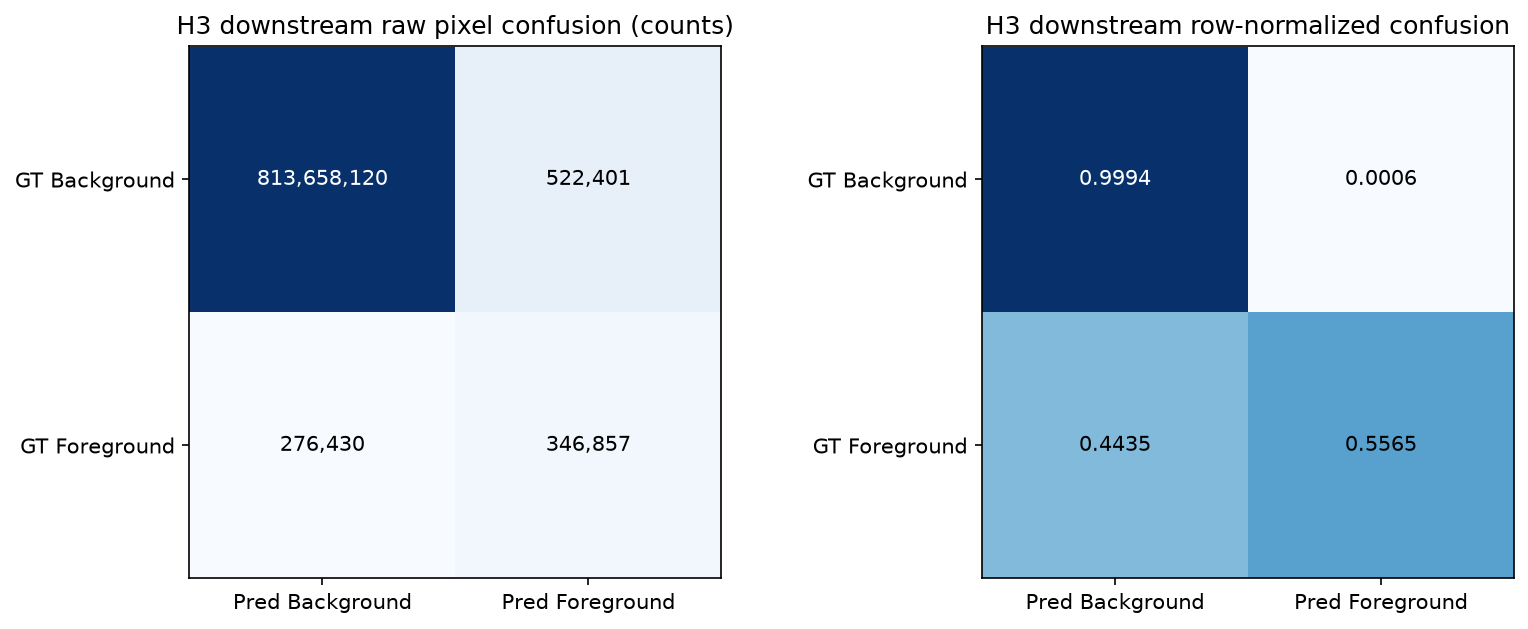

,comparison,metric,n_pairs,mean_difference,ci_low,ci_high,wilcoxon_p,label
0,H3_DOWNSTREAM - GLOBAL,dice,103,-0.247290,-0.292163,-0.200407,1.182160e-13,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT
1,PREDICTED_REGIONAL - GLOBAL,dice,103,-0.217386,-0.258527,-0.175111,3.285292e-14,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT
2,H3_DOWNSTREAM - PREDICTED_REGIONAL,dice,103,-0.029903,-0.051138,-0.008397,2.845474e-03,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT
3,ORACLE_REGIONAL - GLOBAL,dice,103,0.166499,0.124279,0.213573,3.034700e-17,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT


C:\Users\user\AppData\Local\Temp\ipykernel_37316\2410133287.py:64: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


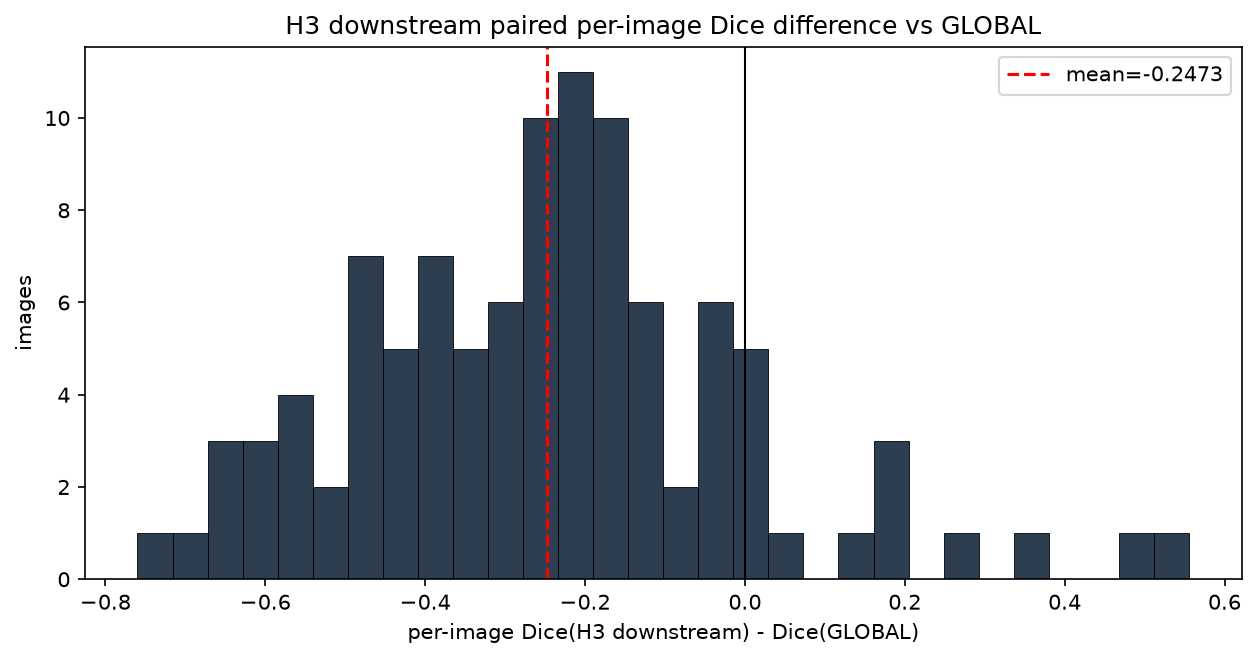

Frozen H3 formal metric unchanged (TinyRecall_H3 = 59/72, R_H3 = 2/15).
All added values are DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE | paired statistics are DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT


In [40]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

conf = _load(_TAB / 'project_evaluation_confusion_matrices.json')
hc = conf['H3_DOWNSTREAM']
fig, axes = _plt.subplots(1, 2, figsize=(11, 4.3))
raw = _np.array(hc['matrix_raw'], dtype=float); nrm = _np.array(hc['matrix_row_normalized'], dtype=float)
axes[0].imshow(_np.log10(raw + 1), cmap='Blues')
for a in range(2):
    for b in range(2):
        axes[0].text(b, a, f'{int(raw[a, b]):,}', ha='center', va='center', fontsize=10,
                     color='black' if raw[a, b] < raw.max() * 0.6 else 'white')
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(['Pred Background', 'Pred Foreground'])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(['GT Background', 'GT Foreground'])
axes[0].set_title('H3 downstream raw pixel confusion (counts)')
axes[1].imshow(nrm, cmap='Blues', vmin=0, vmax=1)
for a in range(2):
    for b in range(2):
        axes[1].text(b, a, f'{nrm[a, b]:.4f}', ha='center', va='center', fontsize=10,
                     color='black' if nrm[a, b] < 0.6 else 'white')
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['Pred Background', 'Pred Foreground'])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(['GT Background', 'GT Foreground'])
axes[1].set_title('H3 downstream row-normalized confusion')
_plt.tight_layout(); _p = _FIG / 'h3_06_confusion.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

pc = _pd.read_csv(_TAB / 'project_evaluation_paired_comparisons.csv')
_disp(pc[['comparison', 'metric', 'n_pairs', 'mean_difference', 'ci_low', 'ci_high', 'wilcoxon_p', 'label']])

pi = _pd.read_csv(_TAB / 'project_evaluation_per_image_metrics.csv')
piv = pi.pivot_table(index='sample_id', columns='arm', values='dice')
if {'H3_DOWNSTREAM', 'GLOBAL'} <= set(piv.columns):
    dd = (piv['H3_DOWNSTREAM'] - piv['GLOBAL']).astype(float)
    fig, ax = _plt.subplots(figsize=(8.5, 4.5))
    ax.hist(dd, bins=30, color='#2c3e50', edgecolor='black', lw=0.4)
    ax.axvline(0, color='black', lw=1); ax.axvline(float(dd.mean()), color='red', ls='--', label=f'mean={dd.mean():.4f}')
    ax.set_xlabel('per-image Dice(H3 downstream) - Dice(GLOBAL)'); ax.set_ylabel('images')
    ax.set_title('H3 downstream paired per-image Dice difference vs GLOBAL')
    ax.legend()
    _plt.tight_layout(); _p = _FIG / 'h3_06_paired_vs_global.png'
    _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

print('Frozen H3 formal metric unchanged (TinyRecall_H3 = 59/72, R_H3 = 2/15).')
print('All added values are', LBL_H3, '| paired statistics are', LBL_STAT)